# 01 · Primer contacto con el habla de T12

Abre una grabación real, muestra la frase que T12 intentó decir y dibuja su actividad neuronal. La sesión, la partición y el ensayo se eligen en la sección 3.

Los textos son referencias del dataset. Las señales se visualizan sin modificar los archivos originales.


## 1. Preparar el entorno

El notebook busca la raíz del proyecto desde la carpeta actual. Funciona tanto desde la raíz como desde `notebooks/`, sin depender de una ruta fija del equipo.

Usamos **NumPy** para las matrices, **SciPy** para los archivos MATLAB y **Matplotlib** para los gráficos. El lector común está en `src/data/speech.py`.

In [5]:
%matplotlib inline
from pathlib import Path
import sys
import html

import numpy as np
import matplotlib.pyplot as plt
import yaml
from scipy.io import whosmat
from IPython.display import display, Markdown

raiz = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "configs/exploration.yaml").is_file()
     and (p / "src/data/speech.py").is_file()),
    None,
)
if raiz is None:
    raise RuntimeError("Abre el notebook desde la raíz del proyecto o su carpeta notebooks/.")
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.data.speech import load_session, inspect_corpus, BIN_SECONDS, AREA_6V_CHANNELS

cfg = yaml.safe_load((raiz / "configs/exploration.yaml").read_text())
carpeta_datos = raiz / cfg["data_root"]
print("Python:", sys.version.split()[0])
print("Datos:", cfg["data_root"])

Python: 3.14.4
Datos: data/speech_2023/competitionData


## 2. Qué tenemos disponible

Un **archivo** representa una sesión y una partición. Dentro tiene varios **ensayos**: cada ensayo es un intento de decir una frase.

El inventario lee los metadatos de todos los `.mat`; no carga simultáneamente sus señales. Las etiquetas de `competitionHoldOut` están ocultas. `train` y `test` comparten días, con bloques diferentes.

In [6]:
inventario = inspect_corpus(carpeta_datos)
splits = ("train", "test", "competitionHoldOut")
filas = []
for nombre in splits:
    archivos = [f for f in inventario if f["split"] == nombre]
    filas.append(f"| {nombre} | {len(archivos)} | {sum(f['trials'] for f in archivos):,} |")
display(Markdown("| Split | Archivos | Ensayos |\n|---|---:|---:|\n" + "\n".join(filas)))

# Lista de sesiones, para copiar una en la celda de selección.
print("Sesiones de train:")
print("\n".join(f["session"] for f in inventario if f["split"] == "train"))

| Split | Archivos | Ensayos |
|---|---:|---:|
| train | 24 | 8,800 |
| test | 24 | 880 |
| competitionHoldOut | 15 | 1,200 |

Sesiones de train:
t12.2022.04.28
t12.2022.05.05
t12.2022.05.17
t12.2022.05.19
t12.2022.05.24
t12.2022.05.26
t12.2022.06.02
t12.2022.06.07
t12.2022.06.14
t12.2022.06.16
t12.2022.06.21
t12.2022.06.23
t12.2022.06.28
t12.2022.07.05
t12.2022.07.14
t12.2022.07.21
t12.2022.07.27
t12.2022.07.29
t12.2022.08.02
t12.2022.08.11
t12.2022.08.13
t12.2022.08.18
t12.2022.08.23
t12.2022.08.25


## 3. Elegir la sesión y la frase


In [7]:
split = cfg["example"]["split"]                    # "train", "test" o "competitionHoldOut"
sesion = cfg["example"]["session"]                # Ejemplo: "t12.2022.04.28"
indice_ensayo = cfg["example"]["trial_index"]       # Cambia a 1, 2, 3... para explorar.

ruta_mat = carpeta_datos / split / f"{sesion}.mat"
if not ruta_mat.is_file():
    raise FileNotFoundError(f"No existe esa sesión en {split}: {sesion}")
print("Archivo seleccionado:", ruta_mat.relative_to(raiz))

Archivo seleccionado: data/speech_2023/competitionData/train/t12.2022.04.28.mat


### Antes de abrir las señales: variables del archivo

`sentenceText` contiene los textos y `blockIdx` identifica el bloque experimental. `spikePow` y `tx1` son arrays de celdas MATLAB: cada celda contiene una matriz **tiempo × canal** de un ensayo.

También existen `tx2`, `tx3` y `tx4`, obtenidos con otros umbrales. El primer lector carga únicamente `spikePow` y `tx1`, además del texto y el bloque.

In [8]:
variables = whosmat(ruta_mat)
filas = [f"| `{nombre}` | `{forma}` | {tipo} |" for nombre, forma, tipo in variables]
display(Markdown("| Variable | Forma MATLAB leída | Tipo |\n|---|---|---|\n" + "\n".join(filas)))

| Variable | Forma MATLAB leída | Tipo |
|---|---|---|
| `sentenceText` | `(280,)` | char |
| `tx1` | `(1, 280)` | cell |
| `tx2` | `(1, 280)` | cell |
| `tx3` | `(1, 280)` | cell |
| `tx4` | `(1, 280)` | cell |
| `spikePow` | `(1, 280)` | cell |
| `blockIdx` | `(280, 1)` | uint8 |

## 4. Abrir un ensayo real

El lector comprueba que texto, bloque y señales correspondan al mismo ensayo; exige matrices con 256 canales, igual número de bins y valores finitos, no negativos.

Un bin dura **20 ms**. La duración calculada es la del fragmento publicado; no tenemos en este archivo una alineación temporal de cada palabra.

In [9]:
registro = load_session(ruta_mat)
if not 0 <= indice_ensayo < len(registro.trials):
    raise ValueError(f"El índice debe estar entre 0 y {len(registro.trials) - 1}.")
ensayo = registro.trials[indice_ensayo]

print("Ensayos en esta sesión:", len(registro.trials))
print("Ensayo:", ensayo.index, "· Bloque:", ensayo.block)
print("spikePow:", ensayo.spike_power.shape, ensayo.spike_power.dtype)
print("tx1:", ensayo.threshold_crossings.shape, ensayo.threshold_crossings.dtype)
print(f"Duración: {ensayo.spike_power.shape[0]} × {BIN_SECONDS} s = {ensayo.duration_seconds:.2f} s")

if ensayo.text is None:
    display(Markdown("**Etiqueta oculta o vacía:** podemos mirar las señales, pero no evaluar una transcripción contra esta referencia."))
else:
    display(Markdown("**Texto de referencia — lo que intentó decir:**\n\n> " + html.escape(ensayo.text)))

Ensayos en esta sesión: 280
Ensayo: 0 · Bloque: 3
spikePow: (478, 256) float32
tx1: (478, 256) uint8
Duración: 478 × 0.02 s = 9.56 s


**Texto de referencia — lo que intentó decir:**

> Nuclear rockets can destroy airfields with ease.

## 5. Visualizar la potencia neuronal: `spikePow`

Las primeras **128 columnas** de cada variable corresponden al área **6v**; las restantes al área **44**. Aquí empezamos por 6v, como recomienda el README del dataset.

`spikePow` es potencia de voltaje de alta frecuencia ya procesada. **No es una señal EEG ni voltaje neuronal crudo.** Cada fila del mapa será un canal y el eje horizontal será el tiempo.

Usamos `log(1 + x)` **solo en este gráfico** para visualizar el rango de potencia. No cambiamos las matrices del lector.

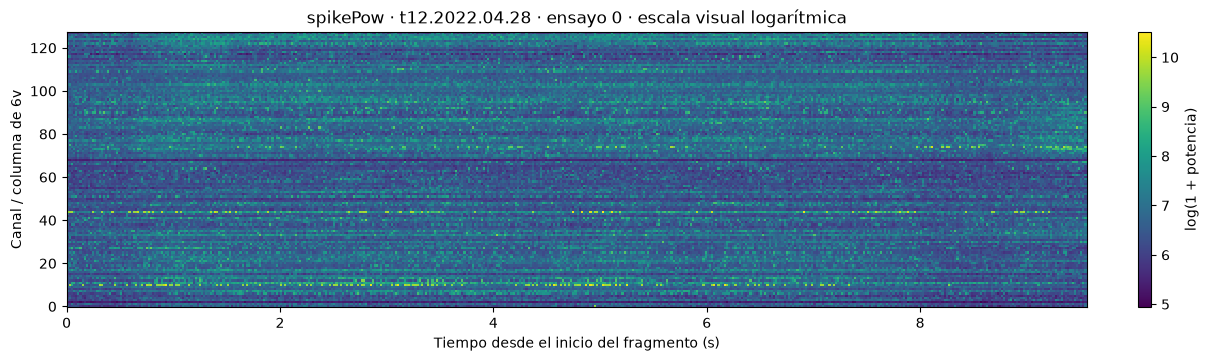

In [10]:
duracion = ensayo.duration_seconds
limites = [0, duracion, -0.5, AREA_6V_CHANNELS - 0.5]

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
mapa = ax.imshow(
    np.log1p(ensayo.spike_power[:, :AREA_6V_CHANNELS]).T,
    origin="lower", aspect="auto", extent=limites,
    interpolation="nearest", cmap="viridis",
)
ax.set(xlabel="Tiempo desde el inicio del fragmento (s)", ylabel="Canal / columna de 6v",
       title=f"spikePow · {sesion} · ensayo {indice_ensayo} · escala visual logarítmica")
fig.colorbar(mapa, ax=ax, label="log(1 + potencia)")
plt.show()

## 6. Visualizar cruces de umbral: `tx1`

`tx1` cuenta las veces que el voltaje cruzó el umbral de −3,5 × RMS durante cada bin de 20 ms. Es una característica relacionada con actividad neuronal cercana al electrodo; no identifica por sí sola palabras.

Mostramos los **conteos originales**, con una escala distinta de la potencia.

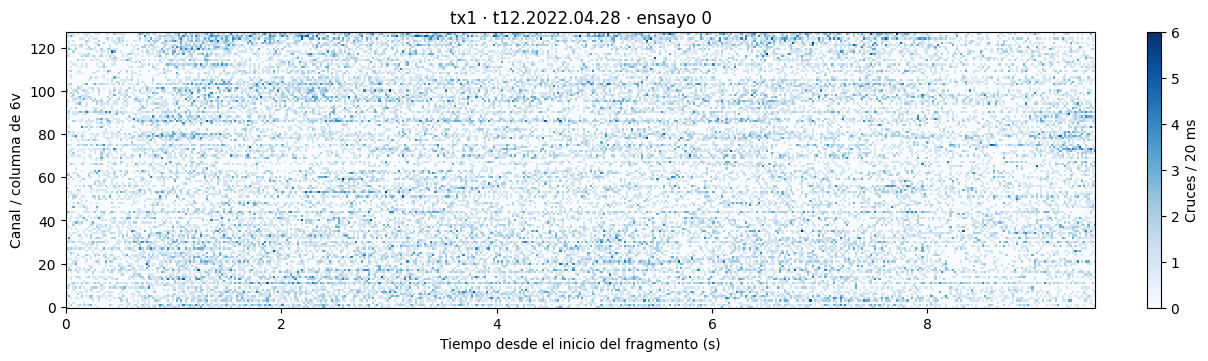

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
mapa = ax.imshow(
    ensayo.threshold_crossings[:, :AREA_6V_CHANNELS].T,
    origin="lower", aspect="auto", extent=limites,
    interpolation="nearest", cmap="Blues",
)
ax.set(xlabel="Tiempo desde el inicio del fragmento (s)", ylabel="Canal / columna de 6v",
       title=f"tx1 · {sesion} · ensayo {indice_ensayo}")
fig.colorbar(mapa, ax=ax, label="Cruces / 20 ms")
plt.show()

### Mostrar canales concretos

Dibuja los canales definidos en `plots.channels` de `configs/exploration.yaml`, sin suavizado ni normalización.


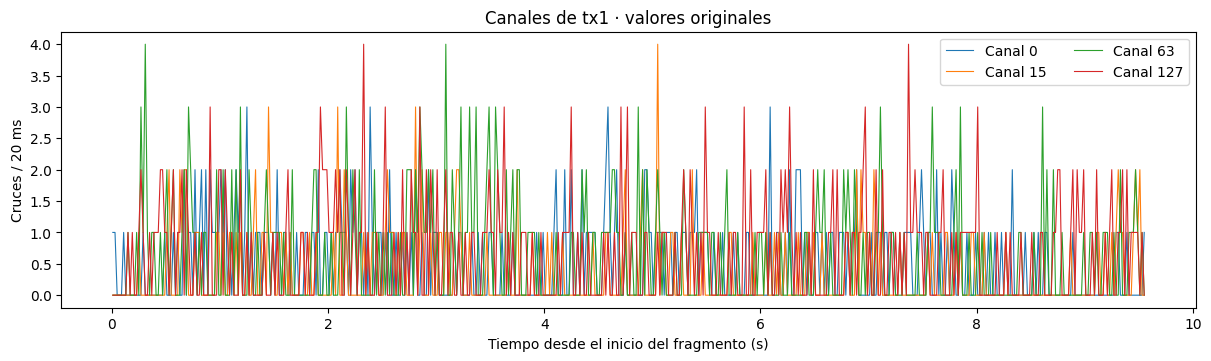

In [8]:
canales = cfg["plots"]["channels"]
tiempo = (np.arange(ensayo.spike_power.shape[0]) + 0.5) * BIN_SECONDS
fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
for canal in canales:
    if not 0 <= canal < AREA_6V_CHANNELS:
        raise ValueError("El canal de 6v debe estar entre 0 y 127.")
    ax.plot(tiempo, ensayo.threshold_crossings[:, canal], label=f"Canal {canal}", linewidth=0.8)
ax.set(xlabel="Tiempo desde el inicio del fragmento (s)", ylabel="Cruces / 20 ms",
       title="Canales de tx1 · valores originales")
ax.legend(ncol=2)
plt.show()

## 7. Duraciones dentro de esta sesión

Cada frase puede tener un número distinto de bins. Para el modelo necesitaremos batches de secuencias de longitud variable.

Esta celda resume **solo la sesión seleccionada**, no todos los valores del corpus. Las estadísticas son descriptivas; no ajustan ninguna normalización.

Mínimo: 4.54 s · Mediana: 10.56 s · Máximo: 18.12 s


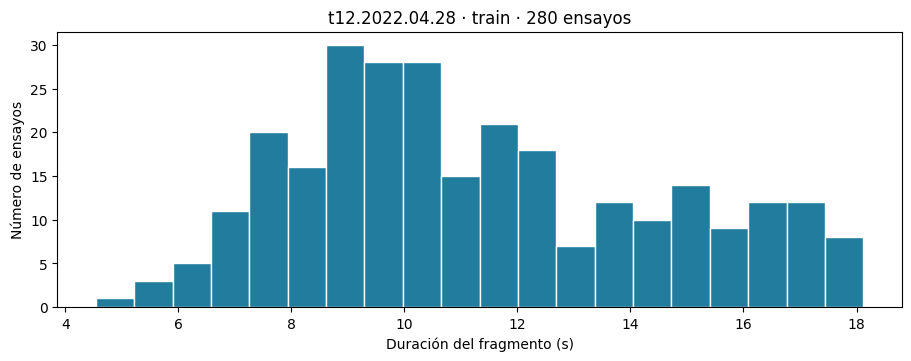

In [9]:
duraciones = np.array([t.duration_seconds for t in registro.trials])
print(f"Mínimo: {duraciones.min():.2f} s · Mediana: {np.median(duraciones):.2f} s · Máximo: {duraciones.max():.2f} s")
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
ax.hist(duraciones, bins=cfg["plots"]["histogram_bins"], color="#227c9d", edgecolor="white")
ax.set(xlabel="Duración del fragmento (s)", ylabel="Número de ensayos",
       title=f"{sesion} · {split} · {len(registro.trials)} ensayos")
plt.show()

## 8. Qué matriz podría recibir el decodificador

Combinamos las **128 columnas de potencia de 6v** con las **128 columnas de conteos de 6v**. El resultado tiene forma **T × 256 características**, no 256 electrodos de 6v.

El orden de columnas es: `spikePow[0:128]`, seguido de `tx1[0:128]`. La matriz es `float32` y aún no está normalizada. Las estadísticas de normalización del futuro entrenamiento deberán ajustarse con train.

In [10]:
x = ensayo.features_6v()
texto_objetivo = ensayo.text
print("Entrada:", x.shape, "·", x.dtype)
print("Columnas 0–127: spikePow de 6v")
print("Columnas 128–255: tx1 de 6v")
print("Texto objetivo:", texto_objetivo if texto_objetivo is not None else "NO DISPONIBLE")
print("No se ha entrenado ni calculado una predicción.")

Entrada: (478, 256) · float32
Columnas 0–127: spikePow de 6v
Columnas 128–255: tx1 de 6v
Texto objetivo: Nuclear rockets can destroy airfields with ease.
No se ha entrenado ni calculado una predicción.


## Fuentes

Formato: README oficial `data/speech_2023/competitionData_readme.txt` y [depósito Dryad](https://datadryad.org/dataset/doi:10.5061/dryad.x69p8czpq). Datos CC0.

El lector está en `src/data/speech.py` y la configuración inicial en `configs/exploration.yaml`.
